# Wrist-Worn Activity Recognition for Unseen Users: Comparing Simple and Compact Models
**ES 335** · [Nityanand Karmali, 24110226.] · [Amartya Tuljapurkar, 24110034.]

**Question.** Can simple ML models recognise a person's activity (sleep, sedentary, light, moderate-vigorous) from 10-second windows of wrist-accelerometer data, for people **not seen in training**? And how much does a compact model (shallow tree, few features) lose compared with a larger one (random forest)?

**Unit and target.** One row = one non-overlapping 10 s window (1,000 samples at 100 Hz). Target = the Walmsley2020 activity class, set to the most frequent label inside the window. A prediction is made when the window ends, using only that window's 16 features (no future windows, no participant ID, no age/sex).

**This is notebook 2 of 2.** Notebook 1 (`capture24-preprocessing`) turned the 152 GB raw CAPTURE-24 data into `capture24_features.parquet` (934,776 labelled windows × 16 features) and `stats.csv`. This notebook trains, evaluates and audits the models and exports small result files for the website.

**Rule we follow.** The test participants (P102–P151) are used **once**, in Section 7. Every choice before that (hyperparameters, number of features, which model is "compact") is made with grouped cross-validation on the training participants (P001–P101) only.

**Claim limit.** Results apply to unseen adults wearing the same wrist device (Axivity AX3) in this dataset's free-living setting. They say nothing about other devices or populations, and predictions are not causal explanations.

## 1. Setup and reproducibility

In [1]:
import os, glob, json, time, shutil, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)

SEED = 42                       # one seed for every random step
np.random.seed(SEED)
OUT = "/kaggle/working/results"
FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)

def dump(obj, name):
    # save a small JSON file for the website
    with open(f"{OUT}/{name}", "w") as f:
        json.dump(obj, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))

def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}", dpi=130); plt.show()

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

python 3.13.18 | numpy 2.1.3 | pandas 2.3.3 | scikit-learn 1.6.1


### Load the feature table from notebook 1
Attach the output of the preprocessing notebook with **Add Input → Your Work → capture24-preprocessing**, or the private dataset holding `capture24_features.parquet` and `stats.csv`. The cell below finds them wherever they are mounted.

In [2]:
def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"/kaggle/working/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found: add notebook 1's output (or your uploaded copy) with 'Add Input'")
    print("using", hits[0])
    return hits[0]

feat  = pd.read_parquet(find("capture24_features.parquet"))
stats = pd.read_csv(find("stats.csv")).drop_duplicates("pid", keep="last")

FEATS   = [f"{a}_{s}" for a in "xyzm" for s in ("mean", "std", "min", "max")]   # the 16 features
CLASSES = ["sleep", "sedentary", "light", "moderate-vigorous"]                   # fixed order for all tables

feat["split"] = np.where(feat["pid"].str[1:].astype(int) <= 101, "train", "test")   # benchmark split, cited

assert set(FEATS) <= set(feat.columns), "feature columns missing"
assert set(feat["label"].unique()) == set(CLASSES), feat["label"].unique()
print(feat.shape)
print(feat["split"].value_counts())
print("participants:", feat["pid"].nunique(), "| train:", feat.loc[feat.split == "train", "pid"].nunique(),
      "| test:", feat.loc[feat.split == "test", "pid"].nunique())

using /kaggle/input/datasets/nityanandkarmali/capture24-features/capture24_features.parquet
using /kaggle/input/datasets/nityanandkarmali/capture24-features/stats.csv
(934776, 21)
split
train    633425
test     301351
Name: count, dtype: int64
participants: 151 | train: 101 | test: 50


## 2. Data understanding
Source: CAPTURE-24 (Chan et al., *Scientific Data* 2024; Oxford Research Archive, DOI 10.5287/bodleian:NGx0JOMP5, CC BY 4.0), used through the Kaggle copy `kooaslansefat/capture-24-human-activity-recognition`. Labels come from wearable-camera images and sleep diaries, mapped to 4 classes with the dataset's own `label:Walmsley2020` column.

Plots of feature behaviour use **training participants only**, so nothing we look at while designing the models comes from the test people.

split               train    test  train %  test %
label                                             
sleep              232341  107890     36.7    35.8
sedentary          258283  112804     40.8    37.4
light              115160   62850     18.2    20.9
moderate-vigorous   27641   17807      4.4     5.9 

windows per participant:
 count     151.0
mean     6191.0
std      1196.0
min      2214.0
25%      5478.0
50%      6259.0
75%      7007.0
max      9009.0
dtype: float64 

moderate-vigorous share per participant:
 count    151.0000
mean       0.0474
std        0.0492
min        0.0000
25%        0.0123
50%        0.0326
75%        0.0673
max        0.2407
Name: label, dtype: float64
27 participants have under 0.5% moderate-vigorous windows


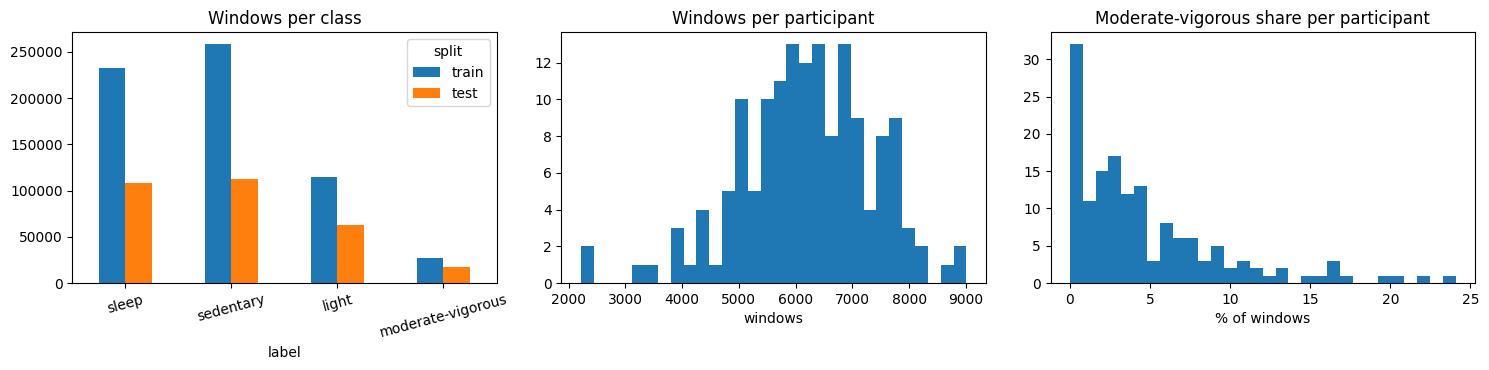

In [3]:
counts = pd.crosstab(feat["label"], feat["split"]).reindex(CLASSES)[["train", "test"]]
share  = (counts / counts.sum() * 100).round(1).add_suffix(" %")
print(pd.concat([counts, share], axis=1), "\n")

per_person = feat.groupby("pid").size()
print("windows per participant:\n", per_person.describe().round(0), "\n")

mv_share = feat["label"].eq("moderate-vigorous").groupby(feat["pid"]).mean()
print("moderate-vigorous share per participant:\n", mv_share.describe().round(4))
print((mv_share < 0.005).sum(), "participants have under 0.5% moderate-vigorous windows")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
counts.plot.bar(ax=ax[0], rot=15, title="Windows per class")
ax[1].hist(per_person, bins=30); ax[1].set_title("Windows per participant"); ax[1].set_xlabel("windows")
ax[2].hist(mv_share * 100, bins=30); ax[2].set_title("Moderate-vigorous share per participant"); ax[2].set_xlabel("% of windows")
savefig("data_overview.png")

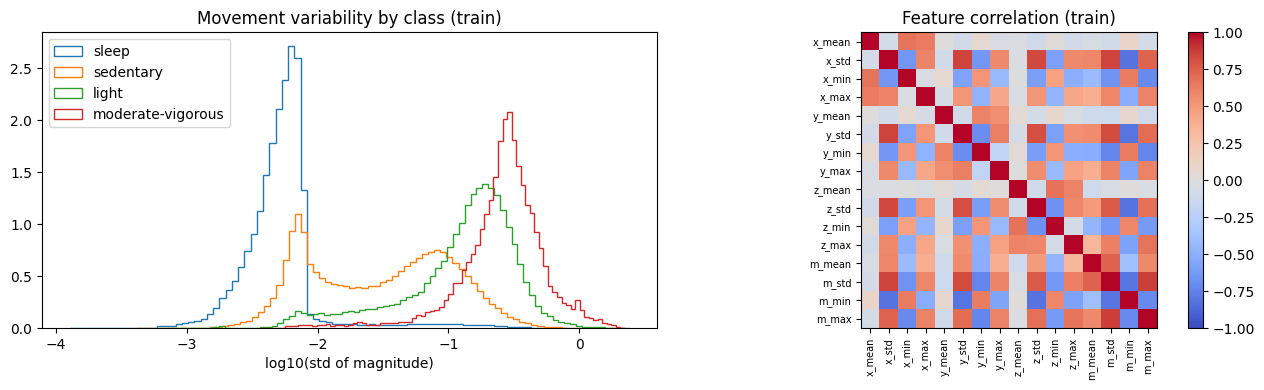

                   m_mean   m_std   m_min   m_max
label                                            
sleep              1.0001  0.0052  0.9854  1.0142
sedentary          1.0021  0.0329  0.8285  1.2133
light              1.0228  0.1542  0.5150  1.8374
moderate-vigorous  1.0487  0.2768  0.3850  2.2569

feature pairs with |correlation| > 0.9:
Series([], dtype: float64)


In [4]:
trd = feat[feat.split == "train"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for c in CLASSES:   # movement variability is the most intuitive feature: does it separate the classes?
    v = trd.loc[trd.label == c, "m_std"]
    ax[0].hist(np.log10(v + 1e-4), bins=80, histtype="step", density=True, label=c)
ax[0].set_xlabel("log10(std of magnitude)"); ax[0].set_title("Movement variability by class (train)"); ax[0].legend()

corr = trd[FEATS].corr()
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_xticks(range(16)); ax[1].set_xticklabels(FEATS, rotation=90, fontsize=7)
ax[1].set_yticks(range(16)); ax[1].set_yticklabels(FEATS, fontsize=7)
ax[1].set_title("Feature correlation (train)"); plt.colorbar(im, ax=ax[1])
savefig("features_by_class.png")

print(trd.groupby("label")[["m_mean", "m_std", "m_min", "m_max"]].median().reindex(CLASSES).round(4))
print("\nfeature pairs with |correlation| > 0.9:")
hi = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print(hi[hi.abs() > 0.9].round(3))

Median movement variability (m_std) rises steadily with intensity: sleep 0.005, sedentary 0.033, light 0.154, moderate-vigorous 0.277. Sleep is the most separated class, but sedentary has two humps: one overlaps sleep (very still sitting) and one overlaps light. Light and moderate-vigorous also overlap heavily. We therefore expect most mistakes between neighbouring intensity levels, and few between sleep and moderate-vigorous.

No feature pair has an absolute correlation above 0.9, so none is an exact duplicate. However, the heatmap shows that the standard-deviation features are strongly related, so some features may add little once others are included. Section 8 tests this

## 3. Data-quality checks (from notebook 1's `stats.csv`)

In [5]:
stats["unlabelled_share"] = 1 - stats["windows_labelled"] / stats["windows_total"]
stats["row_diff_pct"] = 100 * (stats["rows"] - stats["expected_rows"]) / stats["expected_rows"]
print(stats[["share_identical", "unlabelled_share", "row_diff_pct"]].describe().round(3))
print("participants with labels missing from the dictionary:", int((stats["n_unmapped_labels"] > 0).sum()))

GAP_PIDS = sorted(stats.loc[stats["row_diff_pct"].abs() > 1, "pid"])
print("participants whose row count is >1% off (recording gaps):", GAP_PIDS)
print("missing values in the 16 features:", int(feat[FEATS].isna().sum().sum()))

       share_identical  unlabelled_share  row_diff_pct
count          151.000           151.000       151.000
mean             0.334             0.332        -0.430
std              0.040             0.106         1.988
min              0.231             0.156       -13.511
25%              0.308             0.261         0.000
50%              0.330             0.310         0.000
75%              0.361             0.401         0.000
max              0.438             0.681         0.000
participants with labels missing from the dictionary: 0
participants whose row count is >1% off (recording gaps): ['P008', 'P016', 'P017', 'P060', 'P077', 'P094', 'P097', 'P142']
missing values in the 16 features: 0


On average 33.2% of windows per participant had no label and were dropped (range 15.6% to 68.1%), so our results describe labelled time only. On average 33.4% of consecutive samples are exactly identical (range 23.1% to 43.8%). We report this but cannot determine its cause from this data. No features are missing and every raw label is in the dictionary. Eight participants have more than 1% fewer rows than expected, up to 13.5% fewer: seven in train and one in test (P142). Some of their 1,000-row windows may span more than 10 seconds, so Section 10 tests whether this matters

## 4. Preprocessing and the evaluation design (fixed before any model is compared)
- **Split:** participants P001–P101 train, P102–P151 test (CAPTURE-24 benchmark split). No person is in both.
- **Validation:** 5-fold `GroupKFold` with the participant as the group, inside the training set only.
- **Scaling:** only logistic regression needs it. It sits inside a pipeline, so the scaler is re-fit on each training fold and never sees validation or test data. Trees and forests are unaffected by scaling.
- **Feature ranking** (Section 8) is re-done inside every fold.
- **Imbalance:** `class_weight="balanced"`, so mistakes on the rare moderate-vigorous class cost more.
- **Tuning subsample:** neighbouring 10 s windows are near-duplicates, so for tuning we keep every 10th window of each training participant (all 101 people kept). Leaf sizes are given as a *fraction* of the training rows.
- **Metric:** macro-F1 (each class counts equally; accuracy would reward predicting sleep and sedentary). We also report balanced accuracy, per-class recall and confusion matrices.

In [6]:
tr = feat[feat.split == "train"].reset_index(drop=True)
te = feat[feat.split == "test"].reset_index(drop=True)
assert not set(tr.pid) & set(te.pid), "a participant is in both train and test"

sub = tr[tr.groupby("pid").cumcount() % 10 == 0].reset_index(drop=True)    # every 10th window per person
Xs, ys, gs = sub[FEATS], sub["label"], sub["pid"]
gkf = GroupKFold(n_splits=5)
print(f"train {len(tr):,} windows / {tr.pid.nunique()} people | tuning subsample {len(sub):,} | "
      f"test {len(te):,} windows / {te.pid.nunique()} people")

dump({"train_pids": sorted(tr.pid.unique()), "test_pids": sorted(te.pid.unique()),
      "tuning_subsample": "every 10th window per training participant", "cv": "GroupKFold(5) by participant",
      "seed": SEED}, "split.json")

train 633,425 windows / 101 people | tuning subsample 63,385 | test 301,351 windows / 50 people


## 5. Leakage demonstration: random split vs participant split
Same model, same training data, two ways of cross-validating. A random split puts windows from the same person in both training and validation folds, so the model is rewarded for recognising *people* rather than activities. The participant split measures what we actually care about: performance on new people.

In [7]:
demo = {
    "logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "forest":   RandomForestClassifier(n_estimators=100, min_samples_leaf=1, class_weight="balanced",
                                       n_jobs=-1, random_state=SEED),
}
leak = []
for name, m in demo.items():
    rnd = cross_val_score(m, Xs, ys, cv=KFold(5, shuffle=True, random_state=SEED), scoring="f1_macro")
    grp = cross_val_score(m, Xs, ys, cv=gkf, groups=gs, scoring="f1_macro")
    leak.append(dict(model=name, random_split=rnd.mean(), participant_split=grp.mean(),
                     random_std=rnd.std(), participant_std=grp.std(), inflation=rnd.mean() - grp.mean()))
leak = pd.DataFrame(leak)
print(leak.round(3))
dump(leak.to_dict("records"), "leakage.json")

      model  random_split  participant_split  random_std  participant_std  \
0  logistic         0.621              0.614       0.006            0.028   
1    forest         0.743              0.662       0.008            0.028   

   inflation  
0      0.007  
1      0.081  


A random split inflates the forest’s macro-F1 by 0.081 (0.743 vs 0.662 with participant-grouped folds), but logistic regression by only 0.007 (0.621 vs 0.614). With a random split, windows from the same person appear in both training and validation. A flexible forest can learn person-specific patterns, while a linear model with 16 coefficients has little capacity to do so. The participant split is the honest estimate for new users. Because this demo uses every 10th window, immediately neighbouring windows are not present, so the inflation on the full data could differ

## 6. Baselines, candidate models and tuning (training participants only)
| Model | Role | Why it fits this data |
|---|---|---|
| Majority class | floor | what you get by always predicting the most common class |
| Logistic regression | simple baseline | linear, fast, interpretable; a natural first model for 16 numeric features |
| Decision tree, depth ≤ 6 | **compact** model | threshold rules on movement features, readable, tiny |
| Random forest | **large** model | averages many deep trees; handles nonlinear interactions and correlated features |

Each is tuned by 5-fold GroupKFold on the training subsample, choosing the setting with the best mean macro-F1.

In [8]:
MODELS = {
    "majority": (DummyClassifier(strategy="most_frequent"), {}),
    "logistic": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
                 {"logisticregression__C": [0.01, 0.1, 1, 10]}),
    "tree":     (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                 {"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [0.001]}),
    "forest":   (RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=SEED),
                 {"min_samples_leaf": [0.00005, 0.0002, 0.001], "max_features": ["sqrt", 0.5]}),
}
best, cv_rows = {}, []
for name, (est, grid) in MODELS.items():
    t = time.time()
    gs_cv = GridSearchCV(est, grid, cv=gkf, scoring="f1_macro", return_train_score=True, refit=False,
                         n_jobs=1 if name == "forest" else -1)
    gs_cv.fit(Xs, ys, groups=gs)
    r = pd.DataFrame(gs_cv.cv_results_)
    for _, row in r.iterrows():
        cv_rows.append(dict(model=name, params=str(row["params"]), cv_macro_f1=row["mean_test_score"],
                            cv_std=row["std_test_score"], train_macro_f1=row["mean_train_score"]))
    best[name] = gs_cv.best_params_
    print(f"{name:9s} best {gs_cv.best_params_}  CV macro-F1 {gs_cv.best_score_:.3f}  ({time.time() - t:.0f}s)")

cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(f"{OUT}/cv_results.csv", index=False)
print(cv_table.round(3).to_string(index=False))

majority  best {}  CV macro-F1 0.145  (4s)
logistic  best {'logisticregression__C': 10}  CV macro-F1 0.614  (12s)
tree      best {'max_depth': 5, 'min_samples_leaf': 0.001}  CV macro-F1 0.628  (13s)
forest    best {'max_features': 'sqrt', 'min_samples_leaf': 0.0002}  CV macro-F1 0.697  (765s)
   model                                               params  cv_macro_f1  cv_std  train_macro_f1
majority                                                   {}        0.145   0.007           0.145
logistic                      {'logisticregression__C': 0.01}        0.607   0.030           0.615
logistic                       {'logisticregression__C': 0.1}        0.613   0.028           0.622
logistic                         {'logisticregression__C': 1}        0.614   0.028           0.623
logistic                        {'logisticregression__C': 10}        0.614   0.028           0.623
    tree          {'max_depth': 2, 'min_samples_leaf': 0.001}        0.492   0.026           0.492
    tree     

Logistic regression is almost insensitive to C (CV macro-F1 0.607 to 0.614), so regularisation is not its limit. The chosen C = 10 is at the edge of the grid, but the score is flat from C = 1 to 10. The tree’s score improves up to depth 5 (0.628), and depth 6 gives no gain, so we keep the smaller tree.

The forest chose a minimum leaf fraction of 0.0002 (CV 0.697). The smallest leaves fit the training folds best (train 0.953) but validate worse (0.685), a gap of 0.268, which suggests memorisation. The largest leaves shrink the gap to 0.046 but underfit (CV 0.679). The chosen setting is a middle point, though it still has a train-validation gap of 0.134.

## 7. Final fit on all training windows, then the single test evaluation
Every model is refit with its chosen setting on **all** 633k training windows and scored **once** on the 50 test participants.

Uncertainty: windows from one person are highly correlated, so the real sample size is 50 people, not 301k windows. We therefore bootstrap over **test participants** (resample the 50 people with replacement, 1,000 times) to get 95% intervals, and compare models on the same resamples (paired differences).

In [9]:
final, pred, train_f1 = {}, {}, {}
for name, (est, _) in MODELS.items():
    t = time.time()
    m = clone(est).set_params(**best[name])
    if name == "forest":
        m.set_params(n_estimators=200)
    m.fit(tr[FEATS], tr["label"])
    final[name] = m
    pred[name] = m.predict(te[FEATS])
    train_f1[name] = f1_score(tr["label"], m.predict(tr[FEATS]), average="macro")
    print(f"{name:9s} fitted in {time.time() - t:.0f}s")

rows = []
for name, p in pred.items():
    rec = dict(zip(CLASSES, (confusion_matrix(te.label, p, labels=CLASSES).diagonal() /
                             te.label.value_counts().reindex(CLASSES).to_numpy())))
    rows.append(dict(model=name, train_macro_f1=train_f1[name],
                     test_macro_f1=f1_score(te.label, p, average="macro"),
                     balanced_acc=balanced_accuracy_score(te.label, p), accuracy=accuracy_score(te.label, p),
                     **{f"recall_{c}": v for c, v in rec.items()}))
res = pd.DataFrame(rows).set_index("model")
res["gap"] = res["train_macro_f1"] - res["test_macro_f1"]
print(res.round(3).T)
print("\nforest:\n", classification_report(te.label, pred["forest"], labels=CLASSES, digits=3))

majority  fitted in 3s
logistic  fitted in 22s
tree      fitted in 19s
forest    fitted in 471s
model                     majority  logistic   tree  forest
train_macro_f1               0.145     0.617  0.654   0.728
test_macro_f1                0.136     0.631  0.673   0.700
balanced_acc                 0.250     0.669  0.699   0.726
accuracy                     0.374     0.681  0.741   0.757
recall_sleep                 0.000     0.958  0.910   0.897
recall_sedentary             1.000     0.493  0.723   0.709
recall_light                 0.000     0.542  0.506   0.624
recall_moderate-vigorous     0.000     0.682  0.655   0.674
gap                          0.009    -0.014 -0.019   0.028

forest:
                    precision    recall  f1-score   support

            sleep      0.903     0.897     0.900    107890
        sedentary      0.781     0.709     0.743    112804
            light      0.598     0.624     0.611     62850
moderate-vigorous      0.459     0.674     0.546     1780

In [10]:
test_pids = np.array(sorted(te.pid.unique()))
pid_arr, y_true = te["pid"].to_numpy(), te["label"].to_numpy()

def person_cms(y_pred):
    # one 4x4 confusion matrix per test participant (rows = true class)
    return np.stack([confusion_matrix(y_true[pid_arr == p], y_pred[pid_arr == p], labels=CLASSES)
                     for p in test_pids])

def macro_f1(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    fp, fn = cm.sum(-2) - tp, cm.sum(-1) - tp
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0).mean(-1)

CMS = {name: person_cms(p) for name, p in pred.items()}
for name in CMS:   # pooled metric from the per-person matrices must equal sklearn's
    assert np.isclose(macro_f1(CMS[name].sum(0)), res.loc[name, "test_macro_f1"])

rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(test_pids), size=(1000, len(test_pids)))       # 1000 resamples of the 50 people
boot = {name: macro_f1(cms[idx].sum(1)) for name, cms in CMS.items()}

ci = pd.DataFrame({name: dict(macro_f1=res.loc[name, "test_macro_f1"], ci_low=np.percentile(b, 2.5),
                              ci_high=np.percentile(b, 97.5)) for name, b in boot.items()}).T
print(ci.round(3), "\n")

pairs = [("forest", "logistic"), ("forest", "tree"), ("tree", "logistic"), ("logistic", "majority")]
diffs = pd.DataFrame([dict(comparison=f"{a} - {b}", diff=res.loc[a, "test_macro_f1"] - res.loc[b, "test_macro_f1"],
                           ci_low=np.percentile(boot[a] - boot[b], 2.5),
                           ci_high=np.percentile(boot[a] - boot[b], 97.5)) for a, b in pairs])
print(diffs.round(3))

          macro_f1  ci_low  ci_high
majority     0.136   0.126    0.146
logistic     0.631   0.603    0.658
tree         0.673   0.649    0.695
forest       0.700   0.673    0.726 

            comparison   diff  ci_low  ci_high
0    forest - logistic  0.069   0.058    0.080
1        forest - tree  0.027   0.014    0.041
2      tree - logistic  0.042   0.025    0.058
3  logistic - majority  0.495   0.463    0.526


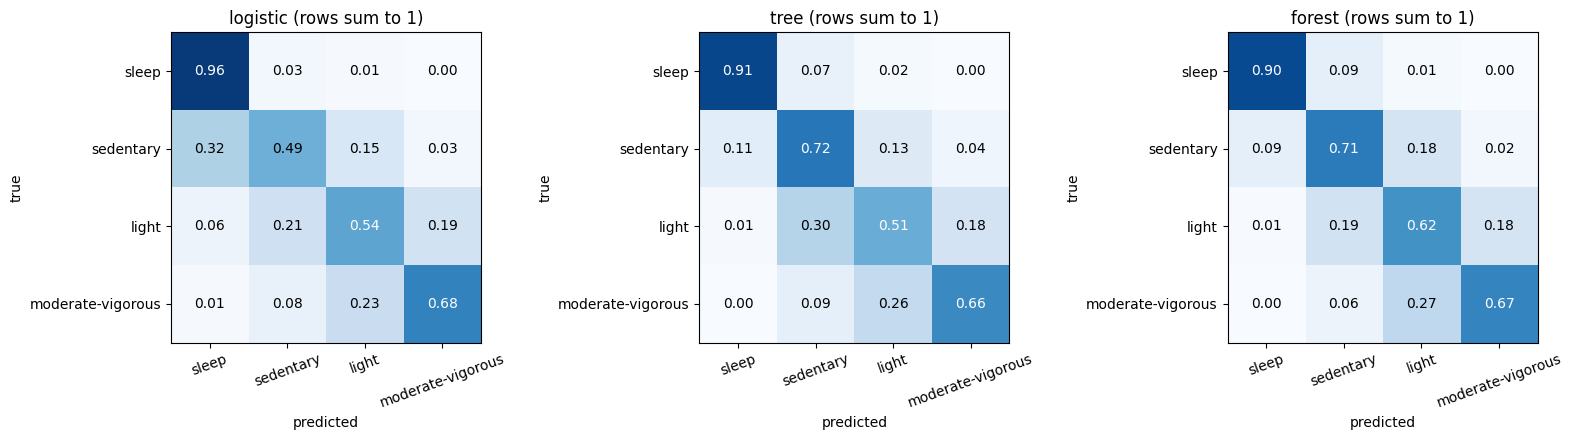

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, name in zip(ax, ["logistic", "tree", "forest"]):
    cm = CMS[name].sum(0)
    cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            a.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > .5 else "black")
    a.set_xticks(range(4)); a.set_xticklabels(CLASSES, rotation=20); a.set_yticks(range(4)); a.set_yticklabels(CLASSES)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"{name} (rows sum to 1)")
savefig("confusion_matrices.png")

All models clearly beat the majority baseline (macro-F1 0.136). Logistic regression adds 0.495 (paired 95% interval 0.463 to 0.526). The final forest reaches 0.700 (0.673 to 0.726) and 75.7% accuracy on unseen people. The forest beats logistic regression by 0.069 (0.058 to 0.080) and the depth-5 tree by 0.027 (0.014 to 0.041). Both intervals exclude 0, so the forest is better on these test participants, but its advantage over a tiny tree is small.

Sleep is easiest (F1 0.900). Moderate-vigorous is weakest (F1 0.546, precision 0.459, recall 0.674). Class weighting finds many of these rare windows, but many of its predictions are false alarms. The most common confusion is sedentary predicted as light (20,234 windows, 17.9% of true sedentary). Logistic regression sends 32% of sedentary windows to sleep, while the tree and forest send only 11% and 9%, which suggests that nonlinear thresholds matter for separating very still sitting from sleep. Test scores are above the CV scores, especially for the tree (0.673 vs 0.628), probably because the test people differ and the final models use more training data, so we do not over-interpret this. We do not compare these scores with published CAPTURE-24 benchmarks, which use richer features.

## 8. Feature budget: how few features are enough? (data for the website slider)
Features are ranked by random-forest importance **using training data only** (re-ranked inside every CV fold). For each budget k = 1…16 we train on the top-k features.
- **CV curve** (training participants): used to *choose* the compact budget = the smallest k whose CV macro-F1 is within 0.01 of the best.
- **Test curve**: reported for the website only; nothing is chosen from it.

These models are trained on the 10% tuning subsample, so their scores differ from Section 7. In our run the k = 16 forest scored about 0.713 on test against 0.700 for the full-data forest, probably because leaf size set as a fraction gives much larger leaves on the full data (train macro-F1 0.831 vs 0.728). We noticed this after testing, so we keep 0.700 as the headline and did not change any model.

In [12]:
def rank_features(X, y):
    rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=0.0002, class_weight="balanced",
                                n_jobs=-1, random_state=SEED).fit(X, y)
    return list(pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).index)

budget_models = {"forest": clone(MODELS["forest"][0]).set_params(**best["forest"]),
                 "tree":   clone(MODELS["tree"][0]).set_params(**best["tree"])}
K = range(1, len(FEATS) + 1)

t = time.time()
cv_curve = {name: {k: [] for k in K} for name in budget_models}
for f_tr, f_va in gkf.split(Xs, ys, gs):
    order = rank_features(Xs.iloc[f_tr], ys.iloc[f_tr])            # ranking sees only this fold's training part
    for k in K:
        cols = order[:k]
        for name, m in budget_models.items():
            m = clone(m).fit(Xs.iloc[f_tr][cols], ys.iloc[f_tr])
            cv_curve[name][k].append(f1_score(ys.iloc[f_va], m.predict(Xs.iloc[f_va][cols]), average="macro"))
print(f"CV curve done in {time.time() - t:.0f}s")

cv_mean = {name: {k: float(np.mean(v)) for k, v in d.items()} for name, d in cv_curve.items()}
best_cv = max(cv_mean["forest"].values())
K_COMPACT = min(k for k, v in cv_mean["forest"].items() if v >= best_cv - 0.01)
print("compact budget chosen by CV:", K_COMPACT, "features")

CV curve done in 995s
compact budget chosen by CV: 8 features


feature ranking: ['z_std', 'm_std', 'x_std', 'y_std', 'm_max', 'm_mean', 'm_min', 'x_mean', 'y_min', 'y_mean', 'z_min', 'z_mean', 'x_min', 'y_max', 'x_max', 'z_max']


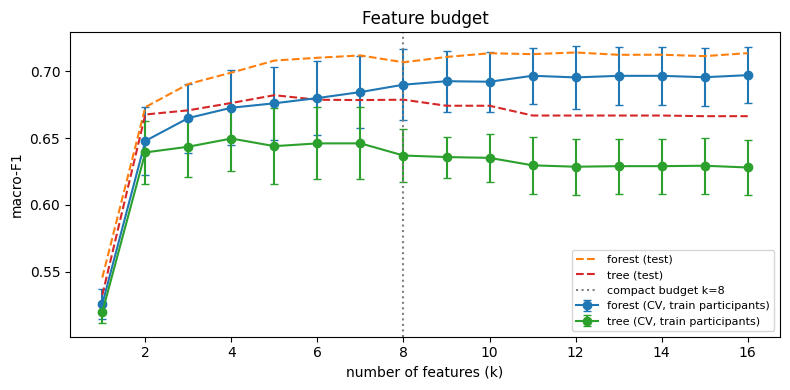

1 {'sleep': np.float64(0.9248), 'sedentary': np.float64(0.4719), 'light': np.float64(0.5151), 'moderate-vigorous': np.float64(0.3921)}
2 {'sleep': np.float64(0.9212), 'sedentary': np.float64(0.6466), 'light': np.float64(0.5774), 'moderate-vigorous': np.float64(0.6299)}
4 {'sleep': np.float64(0.9159), 'sedentary': np.float64(0.6998), 'light': np.float64(0.6105), 'moderate-vigorous': np.float64(0.6112)}
8 {'sleep': np.float64(0.9092), 'sedentary': np.float64(0.7261), 'light': np.float64(0.6108), 'moderate-vigorous': np.float64(0.6266)}
16 {'sleep': np.float64(0.9019), 'sedentary': np.float64(0.7314), 'light': np.float64(0.6504), 'moderate-vigorous': np.float64(0.605)}


In [13]:
ORDER = rank_features(Xs, ys)          # final ranking: all training participants (subsample)
print("feature ranking:", ORDER)

budget = {"order": ORDER, "k_compact": K_COMPACT, "classes": CLASSES, "points": []}
for k in K:
    cols = ORDER[:k]
    point = {"k": k, "features": cols}
    for name, m in budget_models.items():
        p = clone(m).fit(Xs[cols], ys).predict(te[cols])
        cm = confusion_matrix(te.label, p, labels=CLASSES)
        point[name] = {"cv_macro_f1": cv_mean[name][k], "cv_std": float(np.std(cv_curve[name][k])),
                       "test_macro_f1": f1_score(te.label, p, average="macro"),
                       "recall": dict(zip(CLASSES, (cm.diagonal() / cm.sum(1)).round(4))),
                       "confusion": cm.tolist()}
    budget["points"].append(point)
dump(budget, "budget.json")

fig, ax = plt.subplots(figsize=(8, 4))
for name in budget_models:
    ax.errorbar(list(K), [cv_mean[name][k] for k in K], yerr=[np.std(cv_curve[name][k]) for k in K],
                marker="o", capsize=3, label=f"{name} (CV, train participants)")
    ax.plot(list(K), [pt[name]["test_macro_f1"] for pt in budget["points"]], "--", label=f"{name} (test)")
ax.axvline(K_COMPACT, color="grey", ls=":", label=f"compact budget k={K_COMPACT}")
ax.set_xlabel("number of features (k)"); ax.set_ylabel("macro-F1"); ax.legend(fontsize=8)
ax.set_title("Feature budget")
savefig("feature_budget.png")

for k in [1, 2, 4, 8, 16]:     # which class's recall drops first as features are removed
    print(k, budget["points"][k - 1]["forest"]["recall"])

Where the curve flattens. For the forest, CV macro-F1 jumps from 0.526 with one feature to 0.648 with two, then rises slowly and levels off around 0.69–0.70 from k ≈ 9 onwards. The CV rule picked k = 8 (CV 0.690 vs 0.697 at k = 16).

What the compact budget gives up. On test, the 8-feature forest scores 0.707 against 0.713 for all 16 features, a loss of 0.007 (0.7134 vs 0.7065). That is well inside the bootstrap interval width from Section 7. Its moderate-vigorous recall is actually higher (0.627 vs 0.605).

Which class drops first. Sleep is recognised almost as well with one feature (recall 0.925 at k = 1) as with sixteen (0.902), because one movement-variability feature (z_std) separates lying still from everything else. With one feature, moderate-vigorous (0.39) and sedentary (0.47) collapse first. Adding m_std recovers most of both (0.63 and 0.65). Between 8 and 16 features only light activity keeps improving (0.611 → 0.650), so the compact model’s cost falls mainly on the sedentary/light boundary, which is also the most common confusion in Section 7.

Do CV and test agree? Yes, in shape. Both forest curves rise steeply to k = 4–5 and are flat after that; the test curve is about 0.015 higher throughout, as already seen in Section 7. The tree behaves differently from the forest on both curves: it is best with only 3–5 features (CV peak about 0.650 at k = 4, test peak about 0.682 at k = 5) and gets slightly worse as more are added (0.628 CV and 0.666 test at k = 16). A single greedy tree can pick splits on weak features that do not carry over to new people, while the forest averages this out.

## 9. Error audit: which people and which situations fail?
All results here are for the final forest (Section 7). Per-person numbers are reported without participant IDs on the website; age/sex results are group-level only, as the dataset terms require.

       accuracy  balanced_acc  recall_moderate-vigorous
count    50.000        50.000                    46.000
mean      0.752         0.717                     0.675
std       0.085         0.078                     0.243
min       0.527         0.527                     0.000
25%       0.689         0.680                     0.605
50%       0.767         0.723                     0.732
75%       0.821         0.776                     0.845
max       0.885         0.849                     0.973

5 worst participants by balanced accuracy:
 pid  windows  balanced_acc  share_sleep  share_sedentary  share_light  share_moderate-vigorous
P112     3130         0.527        0.690            0.243        0.037                    0.029
P117     5203         0.533        0.352            0.312        0.288                    0.047
P137     5623         0.552        0.438            0.232        0.325                    0.006
P136     4526         0.577        0.239            0.660        0.0

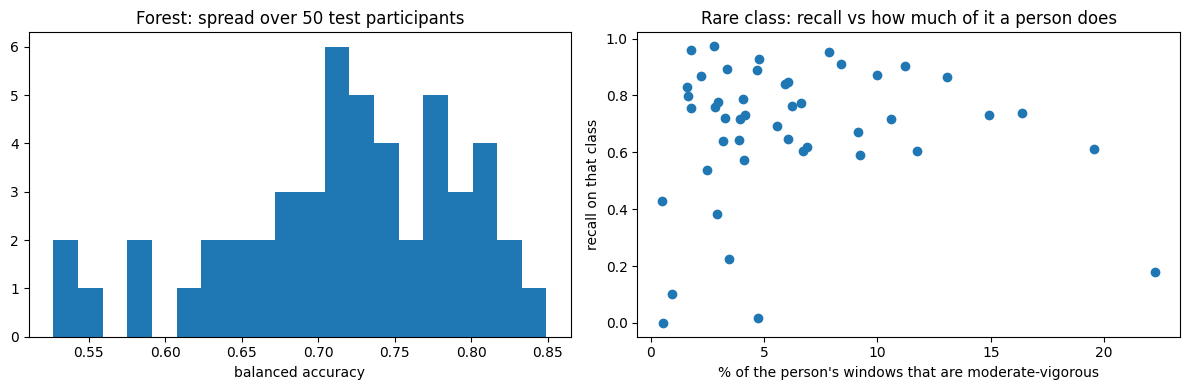

In [14]:
cms = CMS["forest"]
with np.errstate(invalid="ignore", divide="ignore"):
    rec = cms.diagonal(axis1=1, axis2=2) / cms.sum(2)                 # per person, per class recall (NaN if absent)
person = pd.DataFrame({"pid": test_pids, "windows": cms.sum((1, 2)),
                       "accuracy": cms.diagonal(axis1=1, axis2=2).sum(1) / cms.sum((1, 2)),
                       "balanced_acc": np.nanmean(rec, 1)})
for i, c in enumerate(CLASSES):
    person[f"share_{c}"] = cms[:, i, :].sum(1) / person["windows"]
    person[f"recall_{c}"] = np.where(cms[:, i, :].sum(1) >= 20, rec[:, i], np.nan)   # need >= 20 windows
person = person.merge(te.groupby("pid")[["age", "sex"]].first(), left_on="pid", right_index=True)

print(person[["accuracy", "balanced_acc", "recall_moderate-vigorous"]].describe().round(3))
print("\n5 worst participants by balanced accuracy:")
print(person.nsmallest(5, "balanced_acc")[["pid", "windows", "balanced_acc"] +
                                          [f"share_{c}" for c in CLASSES]].round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(person["balanced_acc"], bins=20); ax[0].set_xlabel("balanced accuracy"); ax[0].set_title("Forest: spread over 50 test participants")
ax[1].scatter(person["share_moderate-vigorous"] * 100, person["recall_moderate-vigorous"])
ax[1].set_xlabel("% of the person's windows that are moderate-vigorous"); ax[1].set_ylabel("recall on that class")
ax[1].set_title("Rare class: recall vs how much of it a person does")
savefig("per_person.png")

In [15]:
groups = []
for col in ["sex", "age"]:
    for g, d in person.groupby(col):
        cm = cms[np.isin(test_pids, d["pid"])].sum(0)
        groups.append(dict(attribute=col, group=g, people=len(d), windows=int(cm.sum()), macro_f1=macro_f1(cm),
                           mean_person_balanced_acc=d["balanced_acc"].mean()))
groups = pd.DataFrame(groups)
print(groups.round(3).to_string(index=False))
print("\nGroups have only a handful of people each, so differences here are descriptive, not proof of bias.")

attribute group  people  windows  macro_f1  mean_person_balanced_acc
      sex     F      34   209717     0.718                     0.715
      sex     M      16    91634     0.658                     0.719
      age 18-29      17   100772     0.696                     0.715
      age 30-37      10    62331     0.709                     0.740
      age 38-52      14    86145     0.713                     0.736
      age   53+       9    52103     0.651                     0.663

Groups have only a handful of people each, so differences here are descriptive, not proof of bias.


In [16]:
# representative errors: the most frequent confusions, and what the misclassified windows look like
cm = cms.sum(0)
off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(4) for j in range(4) if i != j]
top = sorted(off, reverse=True)[:3]
print("most frequent confusions (true -> predicted):")
for n, a, b in top:
    print(f"  {a:>17s} -> {b:<17s} {n:,} windows ({n / cm[CLASSES.index(a)].sum():.1%} of true {a})")

te_err = te.assign(pred=pred["forest"])
a, b = top[0][1], top[0][2]
cmp = pd.DataFrame({
    f"true {a}, predicted {a}": te_err[(te_err.label == a) & (te_err.pred == a)][["m_std", "m_mean", "m_max"]].median(),
    f"true {a}, predicted {b}": te_err[(te_err.label == a) & (te_err.pred == b)][["m_std", "m_mean", "m_max"]].median(),
    f"true {b}, predicted {b}": te_err[(te_err.label == b) & (te_err.pred == b)][["m_std", "m_mean", "m_max"]].median(),
})
print("\nmedian feature values (magnitude):\n", cmp.round(4))
print("\nfive example misclassified windows:")
print(te_err[(te_err.label == a) & (te_err.pred == b)].sample(5, random_state=SEED)[FEATS[-4:] + ["label", "pred"]].round(4))

most frequent confusions (true -> predicted):
          sedentary -> light             20,234 windows (17.9% of true sedentary)
              light -> sedentary         11,983 windows (19.1% of true light)
              light -> moderate-vigorous 11,196 windows (17.8% of true light)

median feature values (magnitude):
         true sedentary, predicted sedentary  true sedentary, predicted light  \
m_std                                0.0271                           0.1261   
m_mean                               1.0013                           1.0156   
m_max                                1.1676                           1.7767   

        true light, predicted light  
m_std                        0.1647  
m_mean                       1.0236  
m_max                        1.9403  

five example misclassified windows:
        m_mean   m_std   m_min   m_max      label   pred
77679   1.0386  0.1657  0.5637  1.9365  sedentary  light
187470  1.0053  0.0964  0.5760  1.4218  sedentary  ligh

In [17]:
# compact models side by side (the tree's budget uses the same CV rule as the forest's), and the people
# whose moderate-vigorous windows are mostly missed
rule = max(cv_mean["tree"].values()) - 0.01
k_tree = min(k for k, v in cv_mean["tree"].items() if v >= rule)
pts = {p["k"]: p for p in budget["points"]}
rows = [("forest", 16), ("forest", K_COMPACT), ("tree", 16), ("tree", k_tree)]
compact = pd.DataFrame([{"model": m, "k": k,
                         "cv_macro_f1": pts[k][m]["cv_macro_f1"],
                         "test_macro_f1": pts[k][m]["test_macro_f1"],
                         "recall_mv": pts[k][m]["recall"]["moderate-vigorous"]} for m, k in rows])
print(compact.round(3).to_string(index=False))
dump(compact.to_dict("records"), "compact.json")

low = person[person["recall_moderate-vigorous"] < 0.3]
for pid in low["pid"]:
    row = cms[np.searchsorted(test_pids, pid), 3]
    print(pid, "true MV windows:", row.sum(), dict(zip(CLASSES, (row / row.sum()).round(2).tolist())))

 model  k  cv_macro_f1  test_macro_f1  recall_mv
forest 16        0.697          0.713      0.605
forest  8        0.690          0.707      0.627
  tree 16        0.628          0.666      0.659
  tree  3        0.643          0.671      0.662
P117 true MV windows: 246 {'sleep': 0.02, 'sedentary': 0.57, 'light': 0.39, 'moderate-vigorous': 0.02}
P125 true MV windows: 276 {'sleep': 0.0, 'sedentary': 0.01, 'light': 0.77, 'moderate-vigorous': 0.22}
P129 true MV windows: 1383 {'sleep': 0.0, 'sedentary': 0.06, 'light': 0.76, 'moderate-vigorous': 0.18}
P137 true MV windows: 32 {'sleep': 0.25, 'sedentary': 0.25, 'light': 0.5, 'moderate-vigorous': 0.0}
P138 true MV windows: 49 {'sleep': 0.0, 'sedentary': 0.04, 'light': 0.86, 'moderate-vigorous': 0.1}


Do the errors look like the predicted class? Mostly yes. Sedentary windows predicted as light have median m_std 0.126 and m_max 1.78. That is close to correctly classified light (0.165, 1.94) and far from correctly classified sedentary (0.027, 1.17). In movement terms these windows look like light activity; sitting while gesturing, eating or fidgeting would produce this pattern. A 10 s summary of wrist movement cannot separate them, and camera/diary labels at the boundary between the two classes are probably noisy too. A few errors are not explained by movement (for example a sedentary window with m_std 0.008 predicted as light), so wrist orientation features also play a part.

Which people fail and why. Balanced accuracy per person ranges from 0.527 to 0.849 (median 0.723). Most of the five worst people have very little moderate-vigorous activity: two have under 1% MV windows (P137: 32 windows; P136: under 1%), and P112 is 69% sleep. Balanced accuracy weights each class equally, so a few missed MV windows pull these people down sharply. The scatter plot shows that low MV recall is concentrated in people with under 5% MV. The clear exception is a person with about 22% MV windows (1,383) whose recall is only 0.18: 76% of their MV windows were predicted as light. Their vigorous activity probably involves little wrist movement, which this feature set cannot see. We cannot confirm the activity from the data.

Compact models. The 8-feature forest loses only 0.007 test macro-F1 against 16 features. A depth-5 tree using just 3 features (CV 0.643, test 0.671) does as well as the same tree with all 16 (0.628, 0.666). A small rule-based model on a few movement-variability features is therefore within about 0.04 of the best forest.

Age/sex. Pooled macro-F1 is lower for men (0.658 vs 0.718), but mean per-person balanced accuracy is almost identical (0.719 vs 0.715). The pooled gap most likely reflects a different mix of activities among only 16 men, not worse accuracy per person. The 53+ group is lower on both measures (0.651 and 0.663), but it has only 9 people and no confidence intervals. These numbers are descriptive and do not show bias or its absence.

## 10. Sensitivity check: drop the participants with recording gaps
Refit the final forest without the gap participants (train and test alike) and compare on the same reduced test set.

In [18]:
keep_tr, keep_te = ~tr.pid.isin(GAP_PIDS), ~te.pid.isin(GAP_PIDS)
m = clone(final["forest"]).fit(tr.loc[keep_tr, FEATS], tr.loc[keep_tr, "label"])
sens = dict(gap_participants=GAP_PIDS,
            forest_all_participants=f1_score(te.label[keep_te], pred["forest"][keep_te], average="macro"),
            forest_without_gap_participants=f1_score(te.label[keep_te], m.predict(te.loc[keep_te, FEATS]), average="macro"))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in sens.items()})

{'gap_participants': ['P008', 'P016', 'P017', 'P060', 'P077', 'P094', 'P097', 'P142'], 'forest_all_participants': 0.7008, 'forest_without_gap_participants': 0.701}


Removing the eight participants with recording gaps (seven from train, one from test) leaves the forest’s test macro-F1 effectively unchanged (0.7008 → 0.701). The gaps do not affect our conclusions, so we keep all participants.

## 11. Is the data enough? Learning curve over the number of training people
Inside the training set only: hold out 20 training participants for validation and train the forest on 5…81 of the others (3 random draws each). If the curve is still rising at 81 people, more people would help; if it is flat, more data of the same kind would not.

         mean    std
people              
5       0.568  0.019
10      0.631  0.037
20      0.659  0.014
40      0.677  0.014
81      0.674    NaN


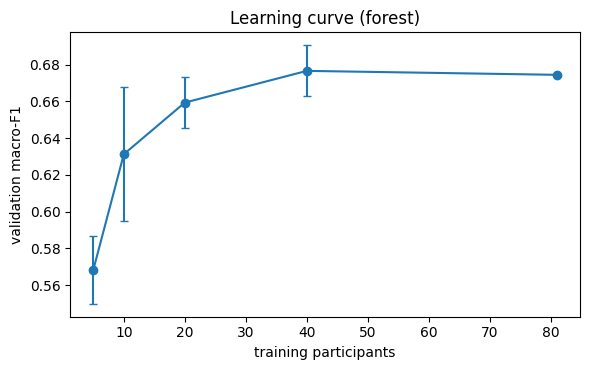

In [19]:
rng_lc = np.random.default_rng(SEED)
train_people = np.array(sorted(sub.pid.unique()))
val_people = rng_lc.choice(train_people, 20, replace=False)
pool = np.setdiff1d(train_people, val_people)
val = sub[sub.pid.isin(val_people)]

lc = []
for n in [5, 10, 20, 40, len(pool)]:
    for rep in range(1 if n == len(pool) else 3):
        people = rng_lc.choice(pool, n, replace=False)
        d = sub[sub.pid.isin(people)]
        m = clone(budget_models["forest"]).fit(d[FEATS], d["label"])
        lc.append(dict(people=n, windows=len(d), val_macro_f1=f1_score(val.label, m.predict(val[FEATS]), average="macro")))
lc = pd.DataFrame(lc)
print(lc.groupby("people")["val_macro_f1"].agg(["mean", "std"]).round(3))

agg = lc.groupby("people")["val_macro_f1"].agg(["mean", "std"]).fillna(0)
plt.figure(figsize=(6, 3.8))
plt.errorbar(agg.index, agg["mean"], yerr=agg["std"], marker="o", capsize=3)
plt.xlabel("training participants"); plt.ylabel("validation macro-F1"); plt.title("Learning curve (forest)")
savefig("learning_curve.png")
dump(lc.to_dict("records"), "learning_curve.json")

Validation macro-F1 rises steeply from 5 to 20 training people (0.568 → 0.659) and flattens after about 40 (0.677 at 40, 0.674 at 81). More participants of the same kind would probably add little with these 16 features. The limit is more likely what 10 s summary features can capture, plus label noise, than the amount of data. Caveats: the 81-person point is a single draw (all remaining people), and validation uses only 20 people.

## 12. Export small result files for the website

In [20]:
dump({"models": res.round(4).reset_index().to_dict("records"),
      "ci": ci.round(4).reset_index(names="model").to_dict("records"),
      "paired_differences": diffs.round(4).to_dict("records"),
      "best_params": best, "classes": CLASSES,
      "confusion": {name: CMS[name].sum(0).tolist() for name in CMS},
      "sensitivity": sens, "groups": groups.round(4).to_dict("records")}, "results.json")

# per-person explorer: anonymised (no participant ID, no age/sex next to individual scores)
anon = person.sample(frac=1, random_state=SEED).reset_index(drop=True)
anon.insert(0, "person", [f"Test person {i + 1}" for i in range(len(anon))])
anon = anon.drop(columns=["pid", "age", "sex"]).round(4)
dump(anon.astype(object).where(anon.notna(), None).to_dict("records"), "persons.json")   # NaN -> null for JS

res.round(4).to_csv(f"{OUT}/test_results.csv")
shutil.make_archive("/kaggle/working/results", "zip", OUT)
print(sorted(os.listdir(OUT)), "\nzip:", os.path.getsize("/kaggle/working/results.zip") // 1024, "KB")

['budget.json', 'compact.json', 'cv_results.csv', 'figures', 'leakage.json', 'learning_curve.json', 'persons.json', 'results.json', 'split.json', 'test_results.csv'] 
zip: 323 KB


## 13. Limitations, disclosure, how to reproduce

**Limitations.**
- **Small test set.** Only 50 test people, so the forest's 95% interval is wide (macro-F1 0.673–0.726). People also vary a lot: per-person balanced accuracy ranges from 0.53 to 0.85.
- **Rare class.** Moderate-vigorous is only 4–6% of windows, and 27 of 151 participants have under 0.5%. Its F1 is the lowest (0.546, precision 0.459), and per-person recall is unreliable for people with few MV windows.
- **Simple features.** 16 summary statistics per 10 s window lose rhythm, frequency and posture-change information. The main confusion (sedentary ↔ light, 17.9% of true sedentary) comes from windows whose movement looks like the predicted class. The learning curve is flat after about 40 people, so the features, not the number of people, are the main limit.
- **Windows treated as independent.** Activities follow each other in time, but each window is classified alone. Temporal smoothing (for example the HMM used in the CAPTURE-24 benchmark) is future work.
- **Label noise.** Labels come from wearable-camera images and sleep diaries, so the boundaries between sedentary and light are uncertain. About a third of windows had no label and were dropped, so results describe labelled time only.
- **Data quality.** About a third of consecutive samples repeat exactly (cause unknown). Eight participants have recording gaps, but removing them does not change the result (0.7008 vs 0.701, Section 10).
- **Tuning on a subsample.** Hyperparameters were tuned on every 10th window, and the forest's leaf size was given as a fraction, so the final full-data forest has larger leaves than the tuned one (Section 8 note).
- **Scope.** One wrist device (Axivity AX3), free-living UK adults in one study. Age/sex groups have 9–34 people, so group differences are descriptive only. Predictions are not causal explanations.

**Pilot disclosure.** Before this notebook we ran an untuned pilot that looked at test scores once as a feasibility check (forest macro-F1 0.707). No setting in this notebook was chosen from that pilot or from test scores. The Section 8 observation about the subsample forest was made after testing and changed nothing.

**AI use.** We used Claude (Anthropic) to brainstorm the project design, draft and debug code, review our outputs and suggest wording for the interpretation text. We ran every cell ourselves, checked the numbers against the outputs, rewrote the text in our own words.

**Reproduce.** (1) Attach the CAPTURE-24 Kaggle copy (`kooaslansefat/capture-24-human-activity-recognition`) and run `capture24-preprocessing` (about 1 hour) to build `capture24_features.parquet` and `stats.csv`. (2) Attach its output to this notebook and **Run All** (seed 42, no GPU, about 1 hour). Library versions are printed in Section 1, and the train/test participant lists are in `results/split.json`. Raw data is not re-published. Cite the Oxford dataset (DOI 10.5287/bodleian:NGx0JOMP5, CC BY 4.0), Chan et al., *Scientific Data* 2024, and the CAPTURE-24 benchmark repository (github.com/OxWearables/capture24) for the split and label grouping.